In [38]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511039/src

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511039/src


In [39]:
# Kode 2.1 Pemisahan kanal dan Kontras Bercak

KB kanal B   : 1.96
KB kanal G   : 2.60
KB kanal R   : 11.22
KB kanal Gray: 6.36
KB kanal H   : 7.15
KB kanal S   : 0.09
KB kanal V   : 4.37


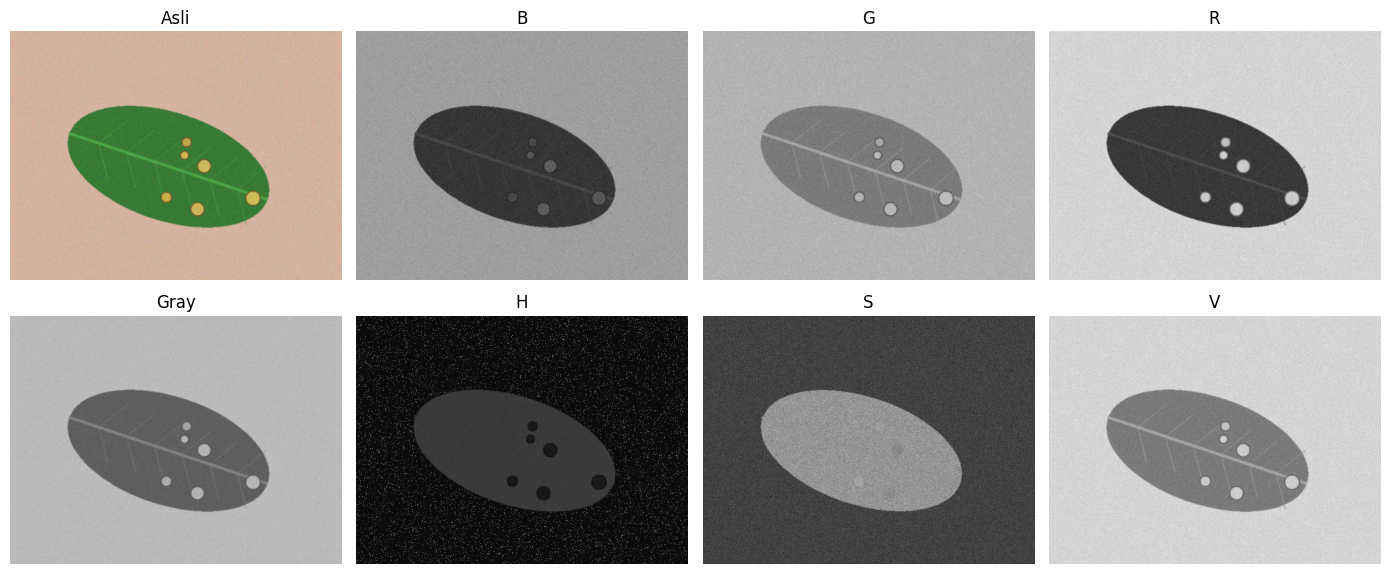

In [40]:
import cv2
from utils_cv import kontras_bercak, baca, tampil
nama = "teh_041.png" # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
 baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
 print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [41]:
# Kode 2.2 Sampling dan kuantisasi

fx=0.5: ukuran (240, 320), KB=7.11
fx=0.2: ukuran (96, 128), KB=5.94
fx=0.1: ukuran (48, 64), KB=3.91
fx=0.05: ukuran (24, 32), KB=1.35
k=1: 2 level, KB=5.73
k=2: 3 level, KB=5.80
k=3: 5 level, KB=3.06
k=4: 10 level, KB=5.24
k=8: 140 level, KB=6.36


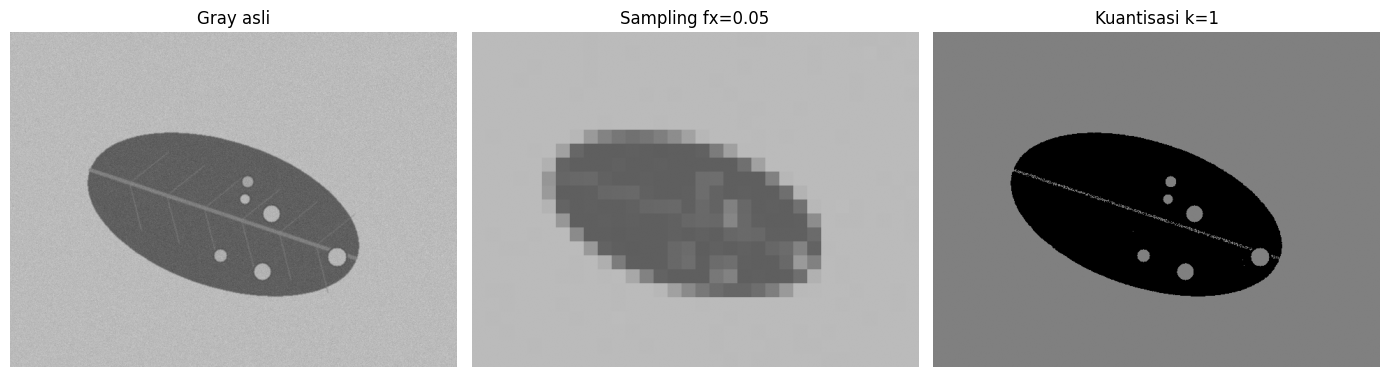

In [45]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")

kecil = cv2.resize(gray, None, fx=0.05, fy=0.05, interpolation=cv2.INTER_AREA)
besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
langkah = 256 // (2 ** 1)
kuant1 = (gray // langkah) * langkah
tampil([gray, besar, kuant1],
       ["Gray asli", "Sampling fx=0.05", "Kuantisasi k=1"], ukuran=(14, 4))

In [43]:
# Kode 2.3 Rerata KB per kanal dan per kondisi


In [44]:
# Kode 2.3 Rerata KB per kanal dan per kondisi
import pandas as pd
def semua_kanal(img):
 hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
 b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
 return {"B": b, "G": g, "R": r,
 "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
 "H": h, "S": s, "V": v}
label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
 im = baca(f"../data/sintetis/citra/{d.nama_file}")
 m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
 m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
# Petunjuk Praktikum Evaluasi P1-P4 Computer Vision | Teknik Informatika UMMI | Halaman 13
 kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
 kb["kondisi"] = d.kondisi_cahaya
 baris.append(kb)
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.18  0.23   5.13  1.58  4.09  1.04  0.84
gelap           1.20  1.09  10.18  4.30  5.87  1.12  2.80
kontras_rendah  0.96  0.48   3.30  2.00  1.39  0.25  1.39
normal          1.89  1.77  10.14  5.26  7.22  0.39  3.44
terang          2.76  1.02   7.25  4.23  5.50  1.30  2.25
